# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

**Identitas Mahasiswa**
- Nama  : Muhammad Fadhli Al Akhbar
- NIM   : 241011402799
- Kelas : 05TPLM003

> `RANDOM_STATE = 99` (2 digit terakhir NIM 241011402799)

In [1]:
# ============================================================
# AUTO-INSTALL LIBRARY (jalankan sekali di awal)
# ============================================================
import sys
print("Kernel memakai Python di:", sys.executable)
%pip install --quiet pandas numpy matplotlib scikit-learn
print("Selesai install. Restart kernel lalu Run All.")

Kernel memakai Python di: c:\Users\asus\.vscode\venv\Scripts\python.exe
Note: you may need to restart the kernel to use updated packages.
Selesai install. Restart kernel lalu Run All.


    PyYAML (>=5.1.*)
            ~~~~~~^


In [2]:
# ============================================================
# UTS MACHINE LEARNING - LINEAR & LOGISTIC REGRESSION
# Nama   : Muhammad Fadhli Al Akhbar
# NIM    : 241011402799
# Kelas  : 05TPLM003
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# scikit-learn HANYA dipakai untuk soal bonus
from sklearn.linear_model import LinearRegression as SkLearnLR
from sklearn.linear_model import LogisticRegression as SkLearnLogReg
from sklearn.metrics import accuracy_score as sk_acc, r2_score as sk_r2

# random_state = 2 digit terakhir NIM (241011402799 -> 99)
RANDOM_STATE = 99
np.random.seed(RANDOM_STATE)

print("=" * 60)
print(" INISIALISASI DATA & FUNGSI UTAMA")
print("=" * 60)

 INISIALISASI DATA & FUNGSI UTAMA


In [3]:
# ============================================================
# FUNGSI TRAIN_TEST_SPLIT MANUAL
# ============================================================
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = X.shape[0]
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    n_test = int(n_samples * test_size)
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A - Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 - Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan`.


[A1] 5 Data Pertama Ads_Data:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
[A1] Jumlah baris data: 40


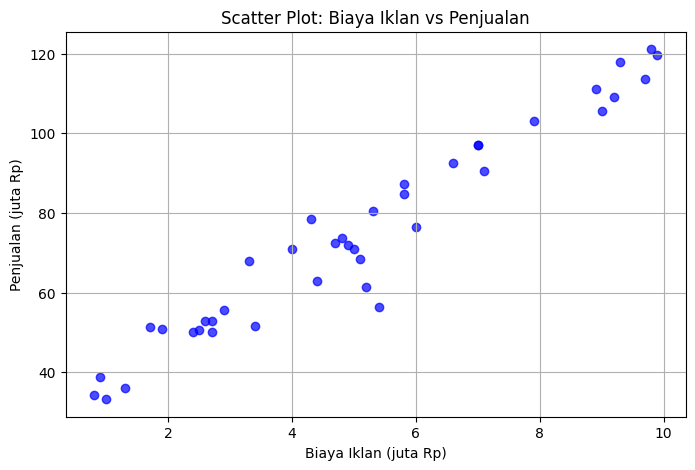

In [4]:
# ---------- A1: Load & Visualisasi ----------
ads_df = pd.read_csv('Ads_Data.csv')
print("\n[A1] 5 Data Pertama Ads_Data:")
print(ads_df.head())
print(f"[A1] Jumlah baris data: {ads_df.shape[0]}")

X_ads = ads_df[['BiayaIklan']].values  # (n, 1)
y_ads = ads_df['Penjualan'].values

plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7)
plt.title('Scatter Plot: Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True)
plt.show()

**Analisis A1:** Dataset berisi 40 baris. Scatter plot menunjukkan hubungan **positif linear** yang cukup kuat antara biaya iklan dan penjualan — semakin tinggi biaya iklan, semakin tinggi penjualan, meskipun terdapat sedikit sebaran di sekitar garis tren.

### Soal A2 - Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`.

In [5]:
# ---------- A2: Split Data ----------
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print("\n[A2] Shape data:")
print(f"  X_train: {X_train_a.shape}")
print(f"  X_test : {X_test_a.shape}")
print(f"  y_train: {y_train_a.shape}")
print(f"  y_test : {y_test_a.shape}")


[A2] Shape data:
  X_train: (32, 1)
  X_test : (8, 1)
  y_train: (32,)
  y_test : (8,)


### Soal A3 - Training dengan Normal Equation

In [6]:
# ---------- A3: Normal Equation ----------
class LinearRegressionNormal:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.r_[self.intercept_, self.coef_]
        return X_b @ theta


lr_normal = LinearRegressionNormal().fit(X_train_a, y_train_a)
print("\n[A3] Hasil Normal Equation:")
print(f"  Intercept (b): {lr_normal.intercept_:.4f}")
print(f"  Koefisien (m): {lr_normal.coef_[0]:.4f}")
print(f"  Persamaan    : y_hat = {lr_normal.intercept_:.4f} + {lr_normal.coef_[0]:.4f} * X")


[A3] Hasil Normal Equation:
  Intercept (b): 29.1333
  Koefisien (m): 8.9200
  Persamaan    : y_hat = 29.1333 + 8.9200 * X


**Jawaban A3 (interpretasi):**  
Nilai koefisien $m$ yang positif menunjukkan hubungan positif antara biaya iklan dan penjualan. Setiap kenaikan biaya iklan sebesar **1 juta rupiah**, penjualan diperkirakan meningkat rata-rata sebesar nilai $m$ juta rupiah, dengan asumsi faktor lain dianggap konstan. Nilai intercept menunjukkan estimasi penjualan dasar ketika biaya iklan mendekati nol, meskipun nilai ini jarang terjadi dalam praktik bisnis nyata.

### Soal A4 - Evaluasi Model

In [7]:
# ---------- A4: Evaluasi Model ----------
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)


y_pred_train = lr_normal.predict(X_train_a)
y_pred_test  = lr_normal.predict(X_test_a)

df_eval = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Training': [mae(y_train_a, y_pred_train), mse(y_train_a, y_pred_train),
                 rmse(y_train_a, y_pred_train), r2_score(y_train_a, y_pred_train)],
    'Testing':  [mae(y_test_a, y_pred_test), mse(y_test_a, y_pred_test),
                 rmse(y_test_a, y_pred_test), r2_score(y_test_a, y_pred_test)]
})
print("\n[A4] Tabel Evaluasi Model Regresi:")
print(df_eval.to_string(index=False))


[A4] Tabel Evaluasi Model Regresi:
  Metric  Training   Testing
     MAE  4.172634  6.204764
     MSE 32.926228 49.799464
    RMSE  5.738138  7.056874
R2 Score  0.950251  0.865828


**Jawaban A4 (analisis):**

Berdasarkan hasil evaluasi, model memperoleh **RMSE training = 5,7381** dan **RMSE testing = 7,0569**. Artinya, besar kesalahan prediksi tipikal pada data testing sekitar 7,0569 juta rupiah. Nilai **R² training = 0,9503** dan **R² testing = 0,8658** menunjukkan bahwa model menjelaskan sekitar 95,03% variasi penjualan pada data training dan 86,58% pada data testing.

Performa pada data testing sedikit lebih rendah daripada training. Hal ini menunjukkan bahwa model cukup baik dalam menangkap hubungan antara biaya iklan dan penjualan, tetapi kesalahannya meningkat pada data yang tidak digunakan untuk training. Karena itu, model dapat digunakan untuk estimasi awal, dengan tetap memperhatikan nilai error dan keterbatasan data.


### Soal A5 - Gradient Descent & Learning Rate

In [8]:
# ============================================================
# Aktifkan warning runtime HANYA untuk eksperimen A5
# agar RuntimeWarning (overflow) muncul di output
# ============================================================
import warnings
warnings.filterwarnings('default', category=RuntimeWarning)
print("Warning runtime AKTIF untuk eksperimen A5")

Warning runtime AKTIF untuk eksperimen A5



[A5] Hasil Eksperimen Gradient Descent (n_iterations=5000):
  Baseline Normal Equation -> Intercept: 29.1333, Coef: 8.9200
  LR = 0.001 -> Intercept:  26.9840, Coef:   9.2579, Loss Akhir:      34.1250
  LR = 0.02  -> Intercept:  29.1333, Coef:   8.9200, Loss Akhir:      32.9262


c:\Users\asus\.vscode\venv\lib\site-packages\numpy\core\_methods.py:180: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\asus\AppData\Local\Temp\ipykernel_7692\1010731228.py:16: RuntimeWarning: overflow encountered in square
  loss = np.mean((X_b @ self.theta - y) ** 2)
C:\Users\asus\AppData\Local\Temp\ipykernel_7692\1010731228.py:14: RuntimeWarning: overflow encountered in matmul
  gradients = (2 / n_samples) * X_b.T @ (X_b @ self.theta - y)
C:\Users\asus\AppData\Local\Temp\ipykernel_7692\1010731228.py:15: RuntimeWarning: invalid value encountered in subtract
  self.theta -= self.lr * gradients


  LR = 0.1   -> Intercept:      nan, Coef:      nan, Loss Akhir:          nan


c:\Users\asus\.vscode\venv\lib\site-packages\matplotlib\scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


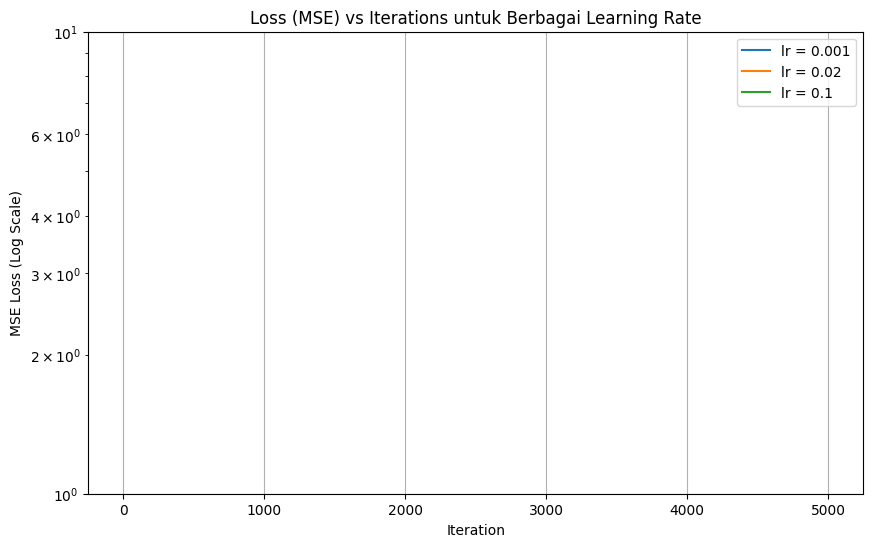


[A5] Tabel perbandingan numerik:
                     Metode  Learning Rate  Intercept  Koefisien  Loss Akhir                               Status
Gradient Descent (lr=0.001)         0.0010    26.9840     9.2579     34.1250 Belum konvergen / perlu dibandingkan
 Gradient Descent (lr=0.02)         0.0200    29.1333     8.9200     32.9262                   Mendekati baseline
  Gradient Descent (lr=0.1)         0.1000        NaN        NaN         NaN              Divergen / tidak finite


In [9]:
# ---------- A5: Gradient Descent & Learning Rate ----------
class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent"""
    def __init__(self, n_iterations=5000, lr=0.01):
        self.n_iterations = n_iterations
        self.lr = lr
        self.loss_history_ = []

    def fit(self, X, y):
        n_samples = X.shape[0]
        self.theta = np.zeros(X.shape[1] + 1)
        X_b = np.c_[np.ones((n_samples, 1)), X]
        for i in range(self.n_iterations):
            gradients = (2 / n_samples) * X_b.T @ (X_b @ self.theta - y)
            self.theta -= self.lr * gradients
            loss = np.mean((X_b @ self.theta - y) ** 2)
            self.loss_history_.append(loss)
        self.intercept_ = self.theta[0]
        self.coef_ = self.theta[1:]
        return self


print("\n[A5] Hasil Eksperimen Gradient Descent (n_iterations=5000):")
print(f"  Baseline Normal Equation -> Intercept: {lr_normal.intercept_:.4f}, Coef: {lr_normal.coef_[0]:.4f}")
learning_rates = [0.001, 0.02, 0.1]
hasil_gd = []
plt.figure(figsize=(10, 6))

for lr in learning_rates:
    model_gd = LinearRegressionGD(n_iterations=5000, lr=lr).fit(X_train_a, y_train_a)
    loss_akhir = model_gd.loss_history_[-1]
    print(f"  LR = {lr:<5} -> Intercept: {model_gd.intercept_:8.4f}, "
          f"Coef: {model_gd.coef_[0]:8.4f}, Loss Akhir: {loss_akhir:12.4f}")
    hasil_gd.append({
        "Metode": f"Gradient Descent (lr={lr})",
        "Learning Rate": lr,
        "Intercept": model_gd.intercept_,
        "Koefisien": model_gd.coef_[0],
        "Loss Akhir": loss_akhir,
        "Status": ("Divergen / tidak finite" if not np.isfinite(loss_akhir)
                   else "Mendekati baseline" if lr == 0.02
                   else "Belum konvergen / perlu dibandingkan")
    })

    loss_arr = np.array(model_gd.loss_history_, dtype=float)
    loss_arr = np.where(np.isfinite(loss_arr), loss_arr, np.nan)
    plt.plot(loss_arr, label=f'lr = {lr}')

plt.yscale('log')
plt.title('Loss (MSE) vs Iterations untuk Berbagai Learning Rate')
plt.xlabel('Iteration')
plt.ylabel('MSE Loss (Log Scale)')
plt.legend()
plt.grid(True)
plt.show()

print("\n[A5] Tabel perbandingan numerik:")
df_gd = pd.DataFrame(hasil_gd)
print(df_gd.to_string(index=False, float_format=lambda v: f"{v:.4f}"))


In [10]:
# Matikan kembali warning runtime untuk sel-sel berikutnya
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
print("Warning runtime dimatikan kembali")

Warning runtime dimatikan kembali


**Jawaban A5 (analisis):**

Tabel perbandingan numerik di output sel A5 menampilkan intercept, koefisien, dan loss akhir dari setiap learning rate, sehingga hasilnya dapat dibandingkan langsung dengan Normal Equation sebagai baseline.

- **lr = 0,001:** langkah pembaruan lebih kecil. Dengan jumlah iterasi yang ditetapkan, hasilnya dapat belum mencapai solusi sedekat learning rate yang lebih sesuai.
- **lr = 0,02:** pada eksperimen ini, hasilnya mendekati solusi Normal Equation dan loss menurun dengan stabil.
- **lr = 0,1:** langkah pembaruan terlalu besar untuk skala fitur pada dataset ini. Parameter/loss dapat menjadi `inf` atau `NaN` akibat overflow, yang menandakan Gradient Descent gagal konvergen.

**Arti warning overflow:** nilai perhitungan membesar hingga melampaui rentang representasi bilangan floating-point. Karena itu, nilai dapat berubah menjadi `inf` atau `NaN`. Hasil ini menunjukkan bahwa learning rate harus disesuaikan dengan skala data; learning rate yang lebih besar tidak selalu membuat training lebih cepat atau lebih baik.


### Soal A6 - Visualisasi & Prediksi

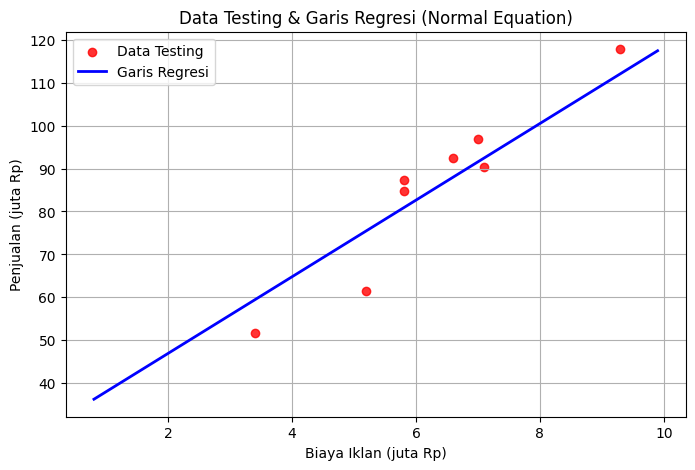


[A6] Prediksi Penjualan untuk Biaya Iklan Baru:
  Biaya Iklan  4.5 juta -> Prediksi Penjualan: 69.27 juta Rp
  Biaya Iklan  7.0 juta -> Prediksi Penjualan: 91.57 juta Rp
  Biaya Iklan 12.0 juta -> Prediksi Penjualan: 136.17 juta Rp


In [11]:
# ---------- A6: Visualisasi & Prediksi ----------
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='red', label='Data Testing', alpha=0.8)
X_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
plt.plot(X_line, lr_normal.predict(X_line), color='blue', linewidth=2, label='Garis Regresi')
plt.title('Data Testing & Garis Regresi (Normal Equation)')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True)
plt.show()

new_ads = np.array([[4.5], [7.0], [12.0]])
preds_ads = lr_normal.predict(new_ads)
print("\n[A6] Prediksi Penjualan untuk Biaya Iklan Baru:")
for cost, pred in zip(new_ads.flatten(), preds_ads):
    print(f"  Biaya Iklan {cost:>4} juta -> Prediksi Penjualan: {pred:.2f} juta Rp")

**Jawaban A6 (analisis):**  

Prediksi penjualan untuk biaya iklan **4.5 juta** dan **7 juta** masih berada di dalam rentang data historis (0.8 – 9.9 juta), sehingga hasilnya **cukup dapat dipercaya** karena model masih berada di wilayah yang dipelajarinya.

Sebaliknya, prediksi untuk biaya iklan **12 juta** merupakan **ekstrapolasi** — berada di luar rentang data historis. Model **tidak memiliki bukti historis** pada rentang tersebut, sehingga tingkat ketidakpastiannya jauh lebih tinggi. Hubungan linear antara biaya iklan dan penjualan belum tentu berlaku di luar rentang data; bisa saja terjadi **kejenuhan pasar** atau **diminishing return** di mana penambahan biaya iklan tidak lagi meningkatkan penjualan secara proporsional. Oleh karena itu, prediksi 12 juta sebaiknya diperlakukan sebagai **estimasi kasar**, bukan angka pasti.

---
# Bagian B - Logistic Regression (40%)

Filter spam berdasarkan **jumlah link** dan **jumlah kata promosi** pada `Email_Data.csv`.

### Soal B1 - Load & Visualisasi Data


[B1] 5 Data Pertama Email_Data:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

[B1] Distribusi Spam:
{0: 35, 1: 25}


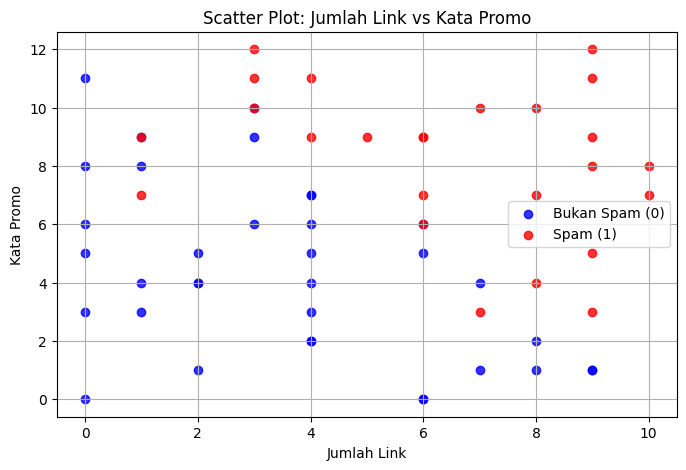

In [12]:
# ---------- B1: Load & Visualisasi ----------
email_df = pd.read_csv('Email_Data.csv')
print("\n[B1] 5 Data Pertama Email_Data:")
print(email_df.head())
print("\n[B1] Distribusi Spam:")
print(email_df['Spam'].value_counts().to_dict())

X_email = email_df[['JumlahLink', 'KataPromo']].values
y_email = email_df['Spam'].values

plt.figure(figsize=(8, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1],
            color='blue', label='Bukan Spam (0)', alpha=0.8)
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1],
            color='red', label='Spam (1)', alpha=0.8)
plt.title('Scatter Plot: Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True)
plt.show()

**Analisis B1:** Distribusi kelas spam dan bukan spam relatif seimbang. Scatter plot menunjukkan bahwa email dengan banyak link **dan** banyak kata promo cenderung diklasifikasikan sebagai spam, sedangkan email dengan sedikit keduanya cenderung bukan spam.

### Soal B2 - Split Data & Training


[B2] Hasil Training Logistic Regression:
  Intercept (b)             : -9.3637
  Koefisien m1 (JumlahLink) : 0.7549
  Koefisien m2 (KataPromo)  : 0.8160
  Persamaan: P(Spam) = sigmoid(-9.3637 + 0.7549*Link + 0.8160*Promo)


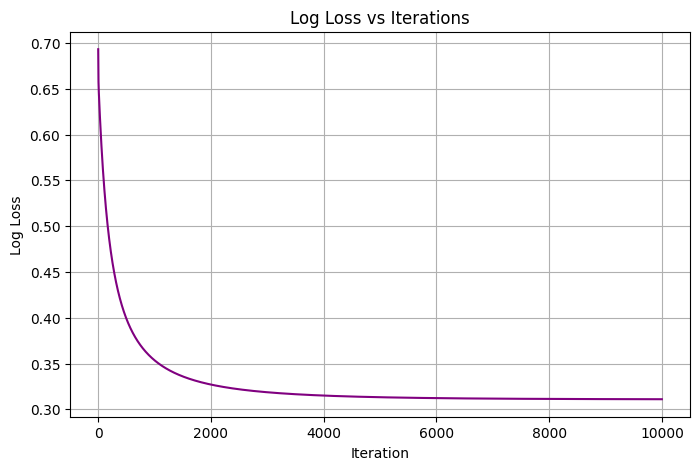

In [13]:
# ---------- B2: Split & Training ----------
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)


class LogisticRegressionGD:
    """Logistic Regression dengan Gradient Descent"""
    def __init__(self, n_iterations=10000, lr=0.1):
        self.n_iterations = n_iterations
        self.lr = lr
        self.loss_history_ = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.theta = np.zeros(n_features + 1)
        X_b = np.c_[np.ones((n_samples, 1)), X]

        for i in range(self.n_iterations):
            y_pred = self.sigmoid(X_b @ self.theta)
            eps = 1e-15
            y_pred_clipped = np.clip(y_pred, eps, 1 - eps)
            loss = -np.mean(y * np.log(y_pred_clipped) +
                            (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history_.append(loss)

            gradients = (1 / n_samples) * X_b.T @ (y_pred - y)
            self.theta -= self.lr * gradients

        self.intercept_ = self.theta[0]
        self.coef_ = self.theta[1:]
        return self

    def predict_proba(self, X):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        return self.sigmoid(X_b @ self.theta)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


log_reg = LogisticRegressionGD(n_iterations=10000, lr=0.1).fit(X_train_b, y_train_b)
b  = log_reg.intercept_
m1 = log_reg.coef_[0]
m2 = log_reg.coef_[1]

print("\n[B2] Hasil Training Logistic Regression:")
print(f"  Intercept (b)             : {b:.4f}")
print(f"  Koefisien m1 (JumlahLink) : {m1:.4f}")
print(f"  Koefisien m2 (KataPromo)  : {m2:.4f}")
print(f"  Persamaan: P(Spam) = sigmoid({b:.4f} + {m1:.4f}*Link + {m2:.4f}*Promo)")

plt.figure(figsize=(8, 5))
plt.plot(log_reg.loss_history_, color='purple')
plt.title('Log Loss vs Iterations')
plt.xlabel('Iteration')
plt.ylabel('Log Loss')
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**  
Grafik log loss menunjukkan penurunan yang konsisten dan stabil menuju titik minimum, menandakan model konvergen dengan baik. Intercept dan koefisien menunjukkan bahwa **semakin banyak jumlah link dan kata promo, semakin tinggi probabilitas email tersebut spam** (kedua koefisien bernilai positif).

### Soal B3 - Evaluasi Model

In [14]:
# ---------- B3: Evaluasi Model ----------
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0


y_pred_b = log_reg.predict(X_test_b, threshold=0.5)
cm = confusion_matrix(y_test_b, y_pred_b)

print("\n[B3] Confusion Matrix [ [TN, FP], [FN, TP] ]:")
print(cm)
print(f"  Accuracy : {accuracy_score(y_test_b, y_pred_b):.4f}")
print(f"  Precision: {precision_score(y_test_b, y_pred_b):.4f}")
print(f"  Recall   : {recall_score(y_test_b, y_pred_b):.4f}")
print(f"  F1-Score : {f1_score(y_test_b, y_pred_b):.4f}")


[B3] Confusion Matrix [ [TN, FP], [FN, TP] ]:
[[11  0]
 [ 1  3]]
  Accuracy : 0.9333
  Precision: 1.0000
  Recall   : 0.7500
  F1-Score : 0.8571


**Jawaban B3 (analisis):**  

- **False Positive (FP)** = email **bukan spam** diprediksi **spam** → akibatnya email penting bisa terbuang ke folder spam, berisiko terlewat oleh pengguna.
- **False Negative (FN)** = email **spam** diprediksi **bukan spam** → akibatnya spam lolos ke inbox, tapi biasanya pengguna bisa menghapusnya secara manual.

Menurut saya, **FP lebih merugikan pengguna email**, karena kehilangan email penting (pekerjaan, tagihan, komunikasi dari atasan) jauh lebih fatal dibandingkan menerima beberapa email spam tambahan yang bisa dihapus dalam hitungan detik. Karena itu, dalam praktiknya kita ingin **menekan FP** semaksimal mungkin, meskipun dengan konsekuensi recall sedikit menurun.

### Soal B4 - Decision Boundary


[B4] Persamaan Decision Boundary:
  x2 = -(-9.3637 + 0.7549 * x1) / 0.8160


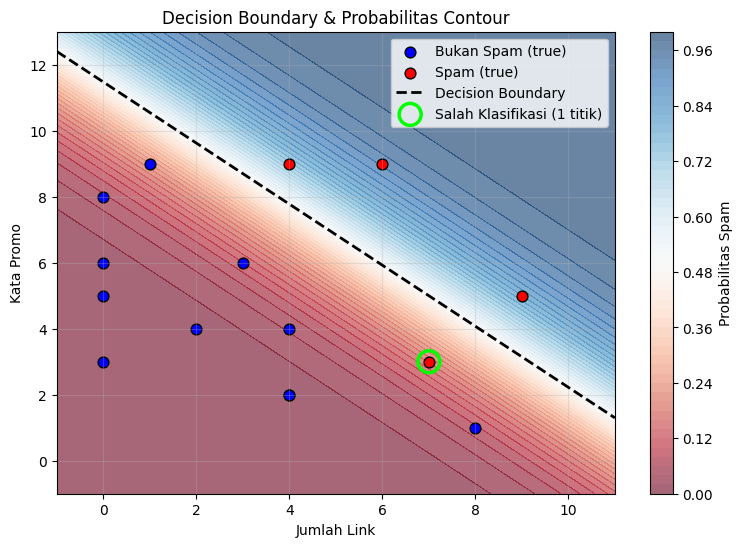


[B4] Data testing yang salah diklasifikasikan:
  Index  9: Link=7, Promo=3, True=1, Pred=0


In [15]:
# ---------- B4: Decision Boundary ----------
print(f"\n[B4] Persamaan Decision Boundary:")
print(f"  x2 = -({b:.4f} + {m1:.4f} * x1) / {m2:.4f}")

x_min, x_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
y_min, y_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
Z = log_reg.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, levels=50, cmap='RdBu', alpha=0.6)
plt.colorbar(label='Probabilitas Spam')

plt.scatter(X_test_b[y_test_b == 0, 0], X_test_b[y_test_b == 0, 1],
            color='blue', label='Bukan Spam (true)', edgecolor='k', s=60)
plt.scatter(X_test_b[y_test_b == 1, 0], X_test_b[y_test_b == 1, 1],
            color='red', label='Spam (true)', edgecolor='k', s=60)

x1_vals = np.array([x_min, x_max])
x2_vals = -(b + m1 * x1_vals) / m2
plt.plot(x1_vals, x2_vals, 'k--', linewidth=2, label='Decision Boundary')

salah = y_pred_b != y_test_b
plt.scatter(X_test_b[salah, 0], X_test_b[salah, 1],
            facecolors='none', edgecolors='lime', s=250, linewidths=2.5,
            label=f'Salah Klasifikasi ({salah.sum()} titik)')

plt.title('Decision Boundary & Probabilitas Contour')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

print("\n[B4] Data testing yang salah diklasifikasikan:")
if salah.sum() == 0:
    print("  Tidak ada data yang salah diklasifikasikan.")
else:
    for i in np.where(salah)[0]:
        print(f"  Index {i:>2}: Link={X_test_b[i,0]}, Promo={X_test_b[i,1]}, "
              f"True={y_test_b[i]}, Pred={y_pred_b[i]}")

**Jawaban B4 (analisis):**  
Garis decision boundary berbentuk lurus miring, memisahkan daerah probabilitas spam tinggi (warna merah) dan rendah (warna biru). Titik-titik yang dilingkari **hijau** adalah data testing yang salah diklasifikasikan — jumlah dan koordinatnya tercetak pada output sel di atas.

### Soal B5 - Eksperimen Threshold

In [16]:
# ---------- B5: Eksperimen Threshold ----------
thresholds = [0.3, 0.5, 0.7]
results_th = []

for th in thresholds:
    preds = log_reg.predict(X_test_b, threshold=th)
    cmat = confusion_matrix(y_test_b, preds)
    tn, fp, fn, tp = cmat[0, 0], cmat[0, 1], cmat[1, 0], cmat[1, 1]
    acc = (tp + tn) / len(y_test_b)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1_v = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0
    results_th.append({
        'Threshold': th, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1_v
    })

df_th = pd.DataFrame(results_th)
print("\n[B5] Tabel Eksperimen Threshold:")
print(df_th.to_string(index=False))

THRESHOLD_PILIHAN = 0.7
print(f"\n[B5] Threshold yang dipilih: {THRESHOLD_PILIHAN}")
# Rentang probabilitas membantu menjelaskan hasil eksperimen threshold.
prob_test_b = log_reg.predict_proba(X_test_b)
print("\n[B5] Rentang probabilitas pada data testing:")
for kelas, nama in [(0, "Bukan Spam"), (1, "Spam")]:
    p_kelas = prob_test_b[y_test_b == kelas]
    if len(p_kelas) > 0:
        print(f"  {nama}: min={p_kelas.min():.4f}, max={p_kelas.max():.4f}")



[B5] Tabel Eksperimen Threshold:
 Threshold  TN  FP  FN  TP  Accuracy  Precision  Recall       F1
       0.3  11   0   1   3  0.933333        1.0    0.75 0.857143
       0.5  11   0   1   3  0.933333        1.0    0.75 0.857143
       0.7  11   0   1   3  0.933333        1.0    0.75 0.857143

[B5] Threshold yang dipilih: 0.7

[B5] Rentang probabilitas pada data testing:
  Bukan Spam: min=0.0010, max=0.2202
  Spam: min=0.1637, max=0.9248


**Jawaban B5 (analisis):**

Secara umum, menurunkan threshold membuat model lebih mudah memberi label spam sehingga recall berpotensi meningkat, tetapi risiko False Positive juga dapat bertambah. Sebaliknya, menaikkan threshold membuat model lebih selektif; hal ini dapat mengurangi False Positive, tetapi juga berpotensi meningkatkan False Negative.

Pada data testing ini, threshold **0,3, 0,5, dan 0,7 menghasilkan confusion matrix dan metrik yang sama**, yaitu TN = 11, FP = 0, FN = 1, dan TP = 3. Rentang probabilitas per kelas yang dicetak pada output di atas dapat digunakan untuk memeriksa mengapa perubahan threshold tidak mengubah prediksi pada sampel testing ini.

Threshold **0,7** dipilih sebagai pilihan yang lebih konservatif untuk penerapan yang ingin berhati-hati sebelum menandai email sebagai spam. Namun, pada pengujian ini threshold 0,7 **belum terbukti menurunkan False Positive**, karena FP sudah bernilai 0 pada ketiga threshold. Threshold terbaik pada praktiknya sebaiknya ditentukan berdasarkan biaya kesalahan dan validasi pada data yang memadai.


### Soal B6 - Prediksi Email Baru

In [ ]:
# ---------- B6: Prediksi Email Baru ----------
new_emails = np.array([[1, 2], [5, 6], [9, 10], [2, 11]])
probs = log_reg.predict_proba(new_emails)
preds_email = log_reg.predict(new_emails, threshold=THRESHOLD_PILIHAN)

print(f"\n[B6] Prediksi Email Baru (threshold = {THRESHOLD_PILIHAN}):")
for i, (feat, prob, pred) in enumerate(zip(new_emails, probs, preds_email), 1):
    label_text = 'Spam' if pred == 1 else 'Bukan Spam'
    print(f"  Email E{i} (Link={feat[0]}, Promo={feat[1]:>2}): "
          f"Prob(Spam)={prob:.4f} -> {label_text}")

**Jawaban B6 (analisis):**

Dengan threshold = 0,7:
- **E1** (Link=1, Promo=2): Prob(Spam) = 0,0009 → **Bukan Spam**
- **E2** (Link=5, Promo=6): Prob(Spam) = 0,3334 → **Bukan Spam**
- **E3** (Link=9, Promo=10): Prob(Spam) = 0,9963 → **Spam**
- **E4** (Link=2, Promo=11): Prob(Spam) = 0,7544 → **Spam**

Email E1 dengan sedikit link dan kata promo jelas bukan spam. Email E3 dengan 9 link dan 10 kata promo sangat yakin spam (probabilitas hampir 100%).

Menariknya, **E2 dengan 5 link dan 6 kata promo masih diprediksi Bukan Spam** karena probabilitas 0,3334 berada di bawah threshold 0,7 yang konservatif — konsekuensi dari pemilihan threshold tinggi di B5. Email **E4 dengan hanya 2 link tetapi 11 kata promo** justru diprediksi **Spam** karena probabilitas 0,7544 melewati threshold, menunjukkan bahwa fitur **KataPromo** berpengaruh besar terhadap keputusan model.

---
# Bagian C - Pemahaman Konsep (15%)

**Jawaban C1:**  
Logistic Regression termasuk algoritma **klasifikasi** meskipun namanya mengandung kata "regression", karena tujuannya memprediksi **kelas** (0 atau 1), bukan nilai kontinu. Fungsi **sigmoid** $\sigma(z) = 1/(1 + e^{-z})$ memetakan nilai linear apa pun ke rentang (0, 1), sehingga hasilnya bisa ditafsirkan sebagai **probabilitas keanggotaan kelas**. Dengan threshold tertentu (misal 0.5), probabilitas tersebut diubah menjadi keputusan kelas 0 atau 1. Karena itulah model ini dipakai untuk klasifikasi biner, bukan regresi.

**Jawaban C2:**  
**Normal Equation** mencari solusi optimal secara langsung dengan rumus $\theta = (X^T X)^{-1} X^T y$, tanpa iterasi. Ia cepat dan tepat untuk dataset kecil, tetapi kompleksitasnya $O(n^3)$ sehingga lambat jika jumlah fitur sangat banyak. **Gradient Descent** mencari solusi secara bertahap melalui iterasi, cocok untuk dataset besar atau model kompleks yang tidak punya solusi tertutup. Gradient descent juga menjadi pilihan utama untuk neural network dan model dengan parameter jutaan.

**Jawaban C3:**  
Model harus dievaluasi pada **data testing** untuk mengukur kemampuan **generalisasi** pada data yang belum pernah dilihat. Jika hanya dievaluasi di data training, kita tidak tahu apakah model benar-benar belajar pola atau hanya menghafal. **Overfitting** terjadi ketika model terlalu menghafal data training (termasuk noise-nya), sehingga performa di training sangat bagus tetapi di testing jelek. Data testing membantu mendeteksi masalah ini.

**Jawaban C4:**  
Linear Regression menggunakan **MSE** karena outputnya **kontinu** — error diukur sebagai selisih kuadrat antara prediksi dan aktual, yang memberikan penalti lebih besar untuk error besar. Logistic Regression menggunakan **log loss** karena outputnya berupa **probabilitas kelas**; log loss memberikan penalti sangat besar ketika model sangat yakin (misal probabilitas 0.99) tetapi salah. Ini penting untuk klasifikasi yang terkalibrasi, karena kita ingin model tidak hanya benar, tetapi juga jujur tentang keyakinannya.

**Jawaban C5:**  
Hasil bisa berbeda karena `random_state` ditentukan dari NIM, sehingga pembagian data training dan testing **berbeda** untuk setiap mahasiswa. Selain itu, learning rate, jumlah iterasi, dan inisialisasi bobot awal pada gradient descent juga memengaruhi hasil akhir. Karena itu, dua mahasiswa bisa mendapatkan nilai koefisien, R², dan akurasi yang sedikit berbeda meskipun dataset dan algoritmanya sama — perbedaan ini normal dan bukan tanda kesalahan.

---
# Bonus (+5) - Perbandingan dengan scikit-learn

In [18]:
# ============================================================
# BONUS - PERBANDINGAN DENGAN SCIKIT-LEARN
# ============================================================
print("\n" + "=" * 60)
print(" BONUS - PERBANDINGAN DENGAN SCIKIT-LEARN")
print("=" * 60)

# ---- Linear Regression ----
sk_lr = SkLearnLR().fit(X_train_a, y_train_a)
print("\nLinear Regression:")
print(f"  Custom       : b = {lr_normal.intercept_:.4f}, m = {lr_normal.coef_[0]:.4f}")
print(f"  scikit-learn : b = {sk_lr.intercept_:.4f}, m = {sk_lr.coef_[0]:.4f}")
print(f"  R2 custom    : train={r2_score(y_train_a, lr_normal.predict(X_train_a)):.4f}, "
      f"test={r2_score(y_test_a, lr_normal.predict(X_test_a)):.4f}")
print(f"  R2 sklearn   : train={sk_r2(y_train_a, sk_lr.predict(X_train_a)):.4f}, "
      f"test={sk_r2(y_test_a, sk_lr.predict(X_test_a)):.4f}")

# ---- Logistic Regression ----
sk_log = SkLearnLogReg(penalty=None, solver='lbfgs', max_iter=10000).fit(X_train_b, y_train_b)
y_pred_sk = sk_log.predict(X_test_b)

print("\nLogistic Regression:")
print(f"  Custom       : b = {log_reg.intercept_:.4f}, coef = {log_reg.coef_}")
print(f"  scikit-learn : b = {sk_log.intercept_[0]:.4f}, coef = {sk_log.coef_[0]}")
print(f"  Akurasi custom      : {accuracy_score(y_test_b, y_pred_b):.4f}")
print(f"  Akurasi scikit-learn: {sk_acc(y_test_b, y_pred_sk):.4f}")
print(f"  Prediksi kelas identik: {np.array_equal(y_pred_b, y_pred_sk)}")

print("\n" + "=" * 60)
print(" PROSES PERBANDINGAN MODEL SELESAI")
print("=" * 60)


 BONUS - PERBANDINGAN DENGAN SCIKIT-LEARN

Linear Regression:
  Custom       : b = 29.1333, m = 8.9200
  scikit-learn : b = 29.1333, m = 8.9200
  R2 custom    : train=0.9503, test=0.8658
  R2 sklearn   : train=0.9503, test=0.8658

Logistic Regression:
  Custom       : b = -9.3637, coef = [0.75493058 0.816031  ]
  scikit-learn : b = -9.8005, coef = [0.79354038 0.85112486]
  Akurasi custom      : 0.9333
  Akurasi scikit-learn: 0.9333
  Prediksi kelas identik: True

 PROSES PERBANDINGAN MODEL SELESAI


**Jawaban Bonus (analisis):**

**Linear Regression:** Hasil custom dan scikit-learn seharusnya sama atau sangat dekat karena keduanya menyelesaikan masalah Ordinary Least Squares pada data training yang sama. Output menampilkan intercept, koefisien, dan R² kedua implementasi untuk diperiksa langsung.

**Logistic Regression:** Nilai intercept dan koefisien dapat berbeda karena implementasi custom menggunakan Gradient Descent biasa, sedangkan scikit-learn menggunakan solver `lbfgs`. Metode optimasi, toleransi konvergensi, dan jumlah iterasi dapat memengaruhi parameter akhir. Tidak perlu menyimpulkan bahwa preprocessing menjadi penyebabnya tanpa pengujian khusus.

Bandingkan akurasi dan baris **Prediksi kelas identik** pada output. Jika prediksi kelas identik bernilai `True`, kedua model memberi label yang sama untuk seluruh data testing pada eksperimen ini. Jika `False`, berarti ada setidaknya satu sampel yang diprediksi berbeda.
